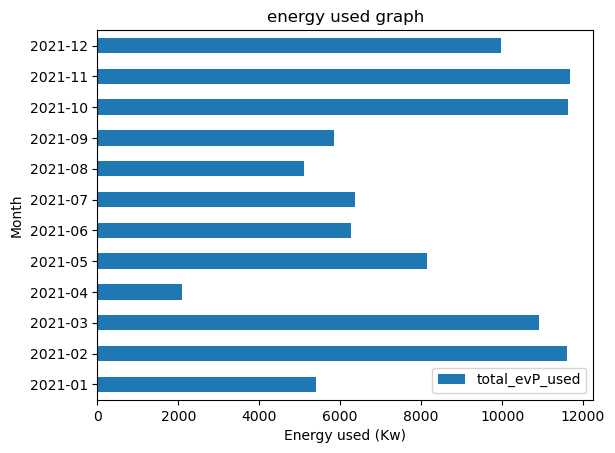

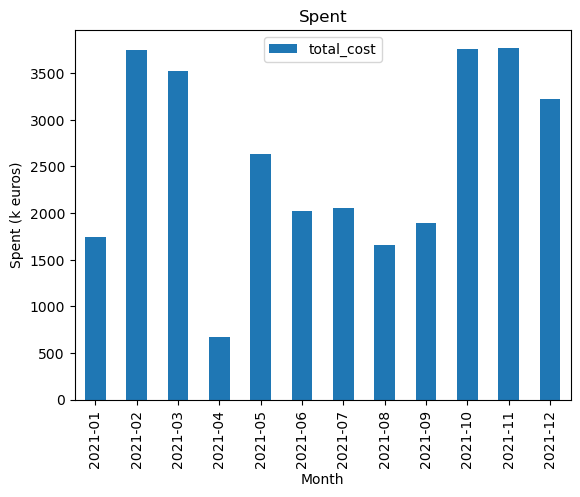

In [42]:
# new line

import pandas as pd

import matplotlib.pyplot as plt



research_collect = pd.read_csv("discovergyTesla1min.csv")


#gathering total power used across 3 phases
total_ev =  research_collect['evP1'] + research_collect['evP2'] + research_collect["evP3"]

total_mains = research_collect["mainsP1"] + research_collect["mainsP2"] + research_collect["mainsP2"]

#putting these gathered powers into the data frame in their own columns
overall_use = research_collect.assign(total_evP_used = total_ev,total_mains_used = total_mains)

#making the timestamps actual timestamps
overall_use['timestamps'] = pd.to_datetime(overall_use['timestamps'])


#grouping data into hours 
hours = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq='h'))[['total_evP_used',"total_mains_used"]].sum()
#grouping data by days
days = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq='D'))[['total_evP_used',"total_mains_used"]].sum()
#grouping data by months
months = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq = 'M'))[['total_evP_used','total_mains_used']].sum()

#using kwh rate in germany to find total energy spent
t = months.assign(total_cost=months['total_evP_used']*0.3234)

#grouping data frame 
x = t.groupby(pd.PeriodIndex(t.index, freq = 'M'))[['total_evP_used','total_mains_used','total_cost']].sum()/1000
d = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq = 'M'))[['total_evP_used','total_mains_used']].sum()




sd_h = hours.std()

sd_d = days.std()

sd_m = months.std()

#energy used graph

(months['total_evP_used']/1000).plot(kind = 'barh')
plt.title('energy used graph')
plt.legend()
plt.xlabel('Energy used (Kw)')
plt.ylabel('Month')
plt.show()


#spendage graph
x['total_cost'].plot(kind = 'bar')
plt.title('Spent')
plt.legend()
plt.ylabel('Spent (k euros)')
plt.xlabel('Month')
plt.show()







In [36]:
days_with_energy_used = days[days['total_evP_used'] > 0]

mean_days_per_month_with_energy_used = days_with_energy_used.resample('M').size().mean()
print(mean_days_per_month_with_energy_used)

8.25


In [37]:
print(monthly_usage.index)

NameError: name 'monthly_usage' is not defined

In [ ]:
import csv

# Open a CSV file for writing ('w' mode)
with open('persons.csv', 'w', newline='') as csvfile:
    filewriter = csv.writer(csvfile, delimiter=',', quotechar='|', quoting=csv.QUOTE_MINIMAL)

    # Write header row
    filewriter.writerow(['timestamp','Name', 'Profession'])

    # Write data rows
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])

r = pd.read_csv('persons.csv')
print(r['timestamp'])
